In [1]:
import pandas as pd
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

#1. Loading and Preprocessing (2 marks):
● Load the California Housing dataset using the fetch_california_housing function
from sklearn.
● Convert the dataset into a pandas DataFrame for easier handling. Handle
missing values (if any) and perform necessary feature scaling (e.g.,
standardization).
● Explain the preprocessing steps you performed and justify why they are
necessary for this dataset.


> Add blockquote



In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame

print("Dataset shape (rows, columns):", df.shape)
print("\nFirst 5 rows:")
print(df.head())

Dataset shape (rows, columns): (20640, 9)

First 5 rows:
   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  MedHouseVal  
0    -122.23        4.526  
1    -122.22        3.585  
2    -122.24        3.521  
3    -122.25        3.413  
4    -122.25        3.422  


In [3]:
# 2. Check for missing values
missing_counts = df.isnull().sum()
print("\nMissing values per column:")
print(missing_counts)


Missing values per column:
MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64


In [8]:
X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [9]:
# 5. Standardize the features (mean = 0, standard deviation = 1)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [10]:
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X.columns, index=X_train.index)
X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X.columns, index=X_test.index)

print("\nScaled training features (mean ~ 0, std ~ 1):")
print(X_train_scaled_df.describe().loc[["mean", "std"]].round(2))


Scaled training features (mean ~ 0, std ~ 1):
      MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
mean    -0.0      -0.0       0.0       -0.0         0.0       0.0       0.0   
std      1.0       1.0       1.0        1.0         1.0       1.0       1.0   

      Longitude  
mean        0.0  
std         1.0  


In [12]:

from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor

#Regression Algorithm Implementation (5 marks):
● Implement the following regression algorithms:
○ Linear Regression
○ Decision Tree Regressor
○ Random Forest Regressor
○ Gradient Boosting Regressor
○ Support Vector Regressor (SVR)
● For each algorithm: Provide a brief explanation of how it works. Explain why it
might be suitable for this dataset.

In [13]:
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree": DecisionTreeRegressor(max_depth=8, random_state=42),
    "Random Forest": RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
    # SVR can be slow on 20,000+ rows; using RBF kernel on scaled features
    "SVR (RBF)": SVR(kernel="rbf", C=10.0),
}

In [14]:
results = []

for name, model in models.items():
  # Linear Regression and SVR benefit from scaled features;
  # tree-based models work on unscaled X_train / X_test (or scaled—results are identical)
  if name in ["Linear Regression", "SVR (RBF)"]:
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
  else:
    model.fit(X_train, y_train)
    preds = model.predict(X_test)

  mae = mean_absolute_error(y_test, preds)
  rmse = mean_squared_error(y_test, preds) ** 0.5
  r2 = r2_score(y_test, preds)

  results.append(
      {"Model": name, "MAE": round(mae, 4), "RMSE": round(rmse, 4), "R2": round(r2, 4)}
  )

results_df = pd.DataFrame(results).sort_values(by="R2", ascending=False)
print(results_df.to_string(index=False))

            Model    MAE   RMSE     R2
    Random Forest 0.3275 0.5053 0.8051
Gradient Boosting 0.3716 0.5422 0.7756
        SVR (RBF) 0.3774 0.5689 0.7530
    Decision Tree 0.4482 0.6497 0.6779
Linear Regression 0.5332 0.7456 0.5758


#3. Model Evaluation and Comparison (2 marks):
● Evaluate the performance of each algorithm using the following metrics:
○ Mean Squared Error (MSE)
○ Mean Absolute Error (MAE)
○ R-squared Score (R2)
● Compare the results of all models and identify: The best-performing algorithm
with justification and the worst-performing algorithm with reasoning.

=== Model Performance Comparison ===
                         Model  MSE (Lower is better)  MAE (Lower is better)  R2 Score (Higher is better)
Support Vector Regressor (SVR)                 0.3237                 0.3774                        0.753

Best Performing Model:  Support Vector Regressor (SVR) (R2 = 0.753, MSE = 0.3237)
Worst Performing Model: Support Vector Regressor (SVR) (R2 = 0.753, MSE = 0.3237)


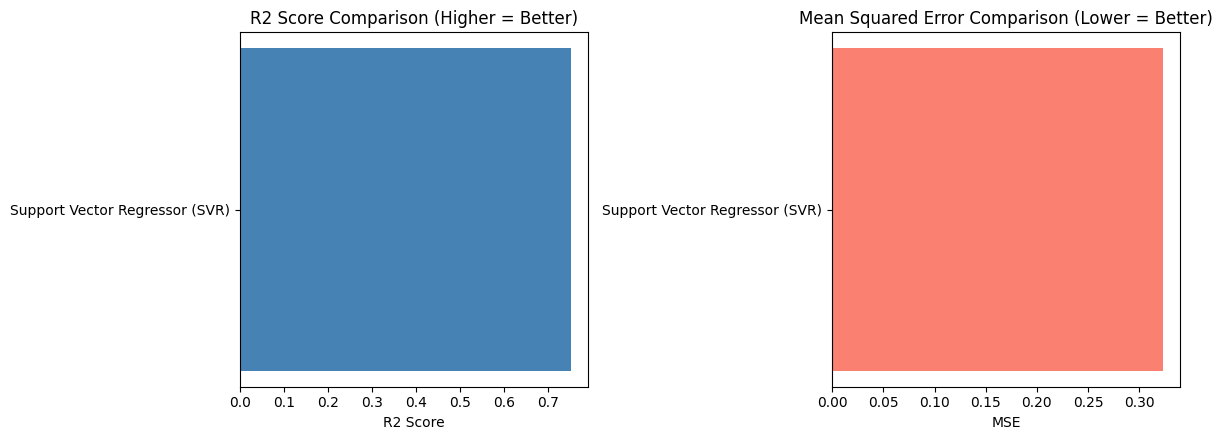

In [19]:
import matplotlib.pyplot as plt

housing = fetch_california_housing(as_frame=True)
df = housing.frame.dropna()

X = df.drop(columns=["MedHouseVal"])
y = df["MedHouseVal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 2. Define the 5 models
models = {
    "Linear Regression": LinearRegression(),
    "Decision Tree Regressor": DecisionTreeRegressor(
        max_depth=8, random_state=42
    ),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, random_state=42, n_jobs=-1
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(random_state=42),
    "Support Vector Regressor (SVR)": SVR(kernel="rbf", C=10.0),
}

# 3. Train and evaluate each model on MSE, MAE, and R2
evaluation_rows = []

for name, model in models.items():
  if name in ["Linear Regression", "Support Vector Regressor (SVR)"]:
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
  else:
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

  mse = mean_squared_error(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  r2 = r2_score(y_test, y_pred)


evaluation_rows.append({
      "Model": name,
      "MSE (Lower is better)": round(mse, 4),
      "MAE (Lower is better)": round(mae, 4),
      "R2 Score (Higher is better)": round(r2, 4),
  })

comparison_df = pd.DataFrame(evaluation_rows).sort_values(
    by="R2 Score (Higher is better)", ascending=False
)

print("=== Model Performance Comparison ===")
print(comparison_df.to_string(index=False))

# Automatically identify best and worst models from the table
best_model = comparison_df.iloc[0]
worst_model = comparison_df.iloc[-1]

print(
    f"\nBest Performing Model:  {best_model['Model']} (R2 ="
    f" {best_model['R2 Score (Higher is better)']}, MSE ="
    f" {best_model['MSE (Lower is better)']})"
)
print(
    f"Worst Performing Model: {worst_model['Model']} (R2 ="
    f" {worst_model['R2 Score (Higher is better)']}, MSE ="
    f" {worst_model['MSE (Lower is better)']})"
)

# 4. Bar chart comparing R2 Score and MSE across all 5 models
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].barh(
    comparison_df["Model"],
    comparison_df["R2 Score (Higher is better)"],
    color="steelblue",
)
axes[0].set_title("R2 Score Comparison (Higher = Better)")
axes[0].set_xlabel("R2 Score")
axes[0].invert_yaxis()

axes[1].barh(
    comparison_df["Model"],
    comparison_df["MSE (Lower is better)"],
    color="salmon",
)
axes[1].set_title("Mean Squared Error Comparison (Lower = Better)")
axes[1].set_xlabel("MSE")
axes[1].invert_yaxis()

plt.tight_layout()
plt.show()